# Ngưỡng cảnh báo sớm cá nhân hóa — chẩn đoán & huấn luyện

Notebook này gộp lại toàn bộ phần chẩn đoán dữ liệu và kết quả Giai đoạn A-B
đã làm trong `data/NHANES/final/{build_watch_feature_table.py, train_watch_model.py,
personalized_band.py}` thành một chỗ chạy được, để xem cùng nhau trước khi làm
tiếp Giai đoạn C.

Kế hoạch đầy đủ: `docs/ML_PERSONALIZED_WATCH_SYSTEM_PLAN.md`.
Bàn giao gốc: `docs/ML_HANDOFF_PERSONALIZED_ATTENTION.md`.

**Cấu trúc:**
1. Chẩn đoán dữ liệu (EDA trên dữ liệu nguồn)
2. Giai đoạn A — xây feature table + kiểm tra leakage
3. Giai đoạn B — train, đánh giá, permutation importance, dải cảnh báo sớm cá nhân (Lớp 3)
4. Tóm tắt & các điểm còn cần quyết định

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3


def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "requirements.txt").exists() and (candidate / "docs").exists():
            return candidate
    raise RuntimeError("could not locate repo root (looked for requirements.txt + docs/)")


REPO_ROOT = find_repo_root(Path.cwd())
FINAL_DIR = REPO_ROOT / "data" / "NHANES" / "final"
ML_DIR = REPO_ROOT / "data" / "ml" / "personalized_watch"
ARTIFACTS_DIR = REPO_ROOT / "artifacts" / "personalized_watch"
sys.path.insert(0, str(FINAL_DIR))

print("REPO_ROOT =", REPO_ROOT)

REPO_ROOT = /Users/phamminh/Desktop/phamminh/AIThucChien/P-158


## Phần 1 — Chẩn đoán dữ liệu

Đọc trực tiếp các file nguồn dùng cho ML — không dùng bản đã build ở Giai đoạn A,
để chẩn đoán độc lập với pipeline.

In [2]:
assessments = pd.read_csv(REPO_ROOT / "data/knowledge_structured/attention_engine/patient_attention_assessments.csv")
glucose = pd.read_csv(REPO_ROOT / "data/simulator_60d/synthetic_glucose_measurements.csv",
                       parse_dates=["measured_at"], low_memory=False)
baselines = pd.read_csv(REPO_ROOT / "data/knowledge_structured/attention_engine/patient_glucose_baselines.csv")
monitoring = pd.read_csv(REPO_ROOT / "data/knowledge_structured/patient_cgm_monitoring_profiles.csv")
targets = pd.read_csv(REPO_ROOT / "data/knowledge_structured/patient_clinical_targets.csv")
clinical = pd.read_csv(REPO_ROOT / "data/NHANES/deployment_dataset/patient_baseline_clinical.csv")
profiles = pd.read_csv(REPO_ROOT / "data/NHANES/deployment_dataset/patient_profiles.csv")
events = pd.read_csv(REPO_ROOT / "data/knowledge_structured/attention_engine/patient_attention_events.csv")

print("assessments:", assessments.shape)
print("glucose measurements:", glucose.shape)
print("unique patients:", assessments["patient_id"].nunique())

assessments: (100470, 21)
glucose measurements: (100470, 23)
unique patients: 489


### 1.1 — Quy mô & phân bố nhãn

status
NORMAL               35659
WATCH                25459
DANGER               20802
BASELINE_LEARNING    18550
Name: count, dtype: int64

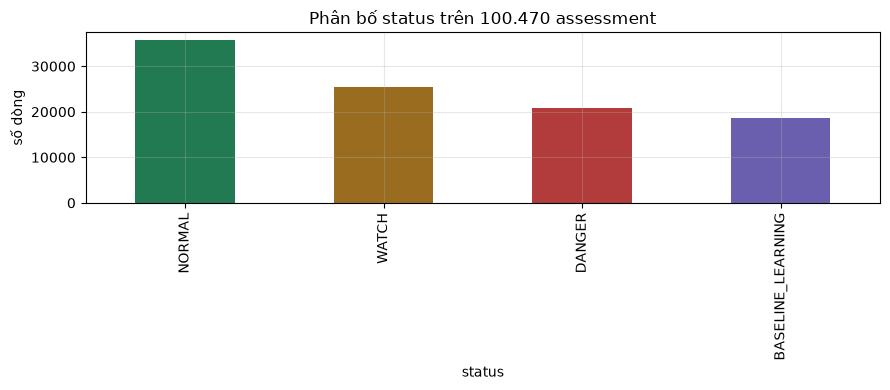

In [3]:
status_counts = assessments["status"].value_counts()
display(status_counts)

fig, ax = plt.subplots()
status_counts.plot(kind="bar", ax=ax, color=["#227a52", "#9a6c1f", "#b23b3b", "#6a5fae"])
ax.set_title("Phân bố status trên 100.470 assessment")
ax.set_ylabel("số dòng")
plt.tight_layout()
plt.show()

### 1.2 — Dữ liệu tự đo rời rạc, không phải CGM liên tục

Khoảng cách giữa hai lần đo liên tiếp của cùng một bệnh nhân, và số lần đo/ngày.

Khoảng cách đo (phút) — describe:


count    99981.000000
mean       419.826897
std        346.084200
min          1.000000
25%        131.000000
50%        345.000000
75%        557.000000
max       2890.000000
Name: gap_min, dtype: float64


Số lần đo/ngày/bệnh nhân — describe:


count    29189.000000
mean         3.442050
std          1.233098
min          1.000000
25%          3.000000
50%          3.000000
75%          4.000000
max          9.000000
dtype: float64

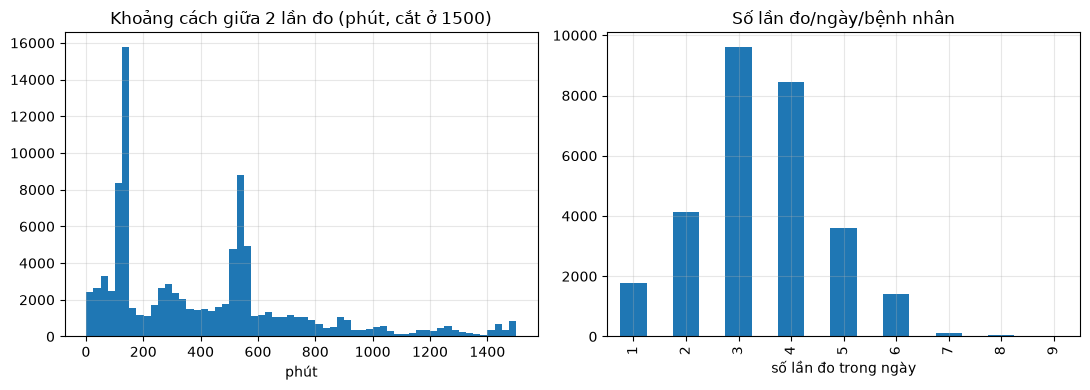

In [4]:
g_sorted = glucose.sort_values(["patient_id", "measured_at"]).copy()
g_sorted["gap_min"] = g_sorted.groupby("patient_id")["measured_at"].diff().dt.total_seconds() / 60

print("Khoảng cách đo (phút) — describe:")
display(g_sorted["gap_min"].describe())

readings_per_day = glucose.assign(date=glucose["measured_at"].dt.date).groupby(["patient_id", "date"]).size()
print("\nSố lần đo/ngày/bệnh nhân — describe:")
display(readings_per_day.describe())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
g_sorted["gap_min"].clip(upper=1500).hist(bins=60, ax=axes[0])
axes[0].set_title("Khoảng cách giữa 2 lần đo (phút, cắt ở 1500)")
axes[0].set_xlabel("phút")
readings_per_day.value_counts().sort_index().plot(kind="bar", ax=axes[1])
axes[1].set_title("Số lần đo/ngày/bệnh nhân")
axes[1].set_xlabel("số lần đo trong ngày")
plt.tight_layout()
plt.show()

### 1.3 — Ngưỡng DANGER: đã có, đã duyệt, nhưng chưa cá nhân hóa

Kiểm tra trực tiếp bảng target thô (không phải bảng monitoring profile đã tổng hợp).

In [5]:
print("Số dòng target:", len(targets), "| số bệnh nhân:", targets["patient_id"].nunique())
print("\nGiá trị target_value theo metric_code — số giá trị khác nhau:")
display(targets.groupby("metric_code")["target_value"].nunique())
print("\nGiá trị duy nhất mỗi loại:")
display(targets.groupby("metric_code")["target_value"].unique())
print("\nTrạng thái:", targets["status"].value_counts().to_dict())
print("Số bác sĩ khác nhau đã duyệt:", targets["approved_by_doctor_id"].nunique(),
      "| số dòng thiếu approved_by_doctor_id:", targets["approved_by_doctor_id"].isna().sum())

Số dòng target: 1467 | số bệnh nhân: 489

Giá trị target_value theo metric_code — số giá trị khác nhau:


metric_code
CGM_DANGER_HIGH     1
CGM_DANGER_LOW      1
CGM_TARGET_RANGE    1
Name: target_value, dtype: int64


Giá trị duy nhất mỗi loại:


metric_code
CGM_DANGER_HIGH        [250]
CGM_DANGER_LOW          [54]
CGM_TARGET_RANGE    [70|180]
Name: target_value, dtype: object


Trạng thái: {'ACTIVE': 1467}
Số bác sĩ khác nhau đã duyệt: 127 | số dòng thiếu approved_by_doctor_id: 0


### 1.4 — Lệch mạnh theo bệnh nhân, tương quan với HbA1c / glucose đói

`danger_rate` = tỉ lệ bản ghi có status DANGER trên tổng số bản ghi của mỗi bệnh nhân.

Bệnh nhân >50% DANGER: 65 / 489

Tương quan:


,danger_rate,hba1c_pct,fasting_glucose_mg_dl
danger_rate,1.000000,0.789381,0.889305
hba1c_pct,0.789381,1.000000,0.730503
fasting_glucose_mg_dl,0.889305,0.730503,1.000000


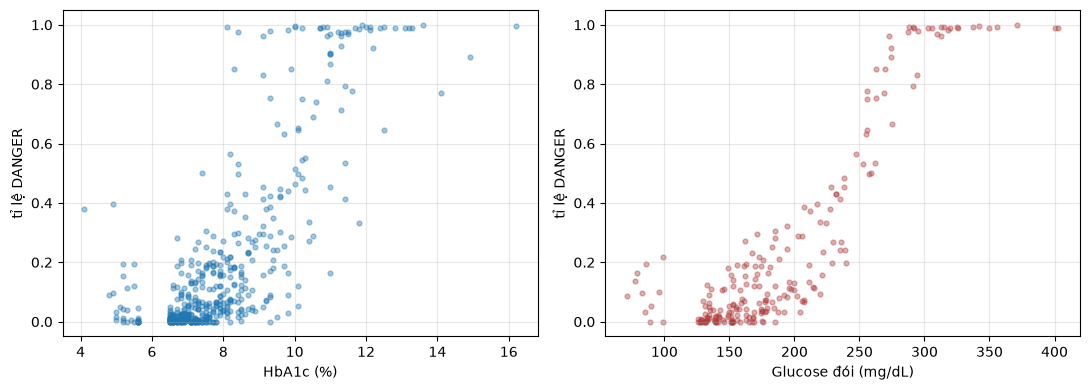

In [6]:
summary = assessments.groupby("patient_id")["status"].agg(
    total="size", danger=lambda s: (s == "DANGER").sum()
)
summary["danger_rate"] = summary["danger"] / summary["total"]
merged = summary.merge(clinical[["patient_id", "hba1c_pct", "fasting_glucose_mg_dl"]], on="patient_id")

print("Bệnh nhân >50% DANGER:", (merged["danger_rate"] > 0.5).sum(), "/", len(merged))
print("\nTương quan:")
display(merged[["danger_rate", "hba1c_pct", "fasting_glucose_mg_dl"]].corr())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(merged["hba1c_pct"], merged["danger_rate"], alpha=0.4, s=12)
axes[0].set_xlabel("HbA1c (%)"); axes[0].set_ylabel("tỉ lệ DANGER")
axes[1].scatter(merged["fasting_glucose_mg_dl"], merged["danger_rate"], alpha=0.4, s=12, color="#b23b3b")
axes[1].set_xlabel("Glucose đói (mg/dL)"); axes[1].set_ylabel("tỉ lệ DANGER")
plt.tight_layout()
plt.show()

### 1.5 — Baseline cá nhân hóa còn khá mỏng

baseline_usable:


baseline_usable
True     1656
False     486
Name: count, dtype: int64


Số điểm/baseline — describe (tối thiểu cần 5):


count    2142.000000
mean        8.660131
std         5.574202
min         0.000000
25%         5.000000
50%         9.000000
75%        12.000000
max        33.000000
Name: baseline_point_count, dtype: float64

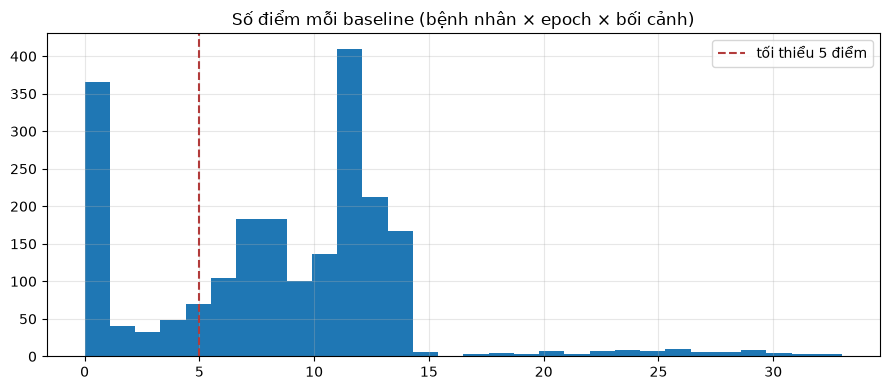

In [7]:
print("baseline_usable:")
display(baselines["baseline_usable"].value_counts())
print("\nSố điểm/baseline — describe (tối thiểu cần 5):")
display(baselines["baseline_point_count"].describe())

fig, ax = plt.subplots()
baselines["baseline_point_count"].hist(bins=30, ax=ax)
ax.axvline(5, color="#b23b3b", linestyle="--", label="tối thiểu 5 điểm")
ax.set_title("Số điểm mỗi baseline (bệnh nhân × epoch × bối cảnh)")
ax.legend()
plt.tight_layout()
plt.show()

### 1.6 — Hai cấp độ nhãn: assessment vs event (sau cooldown)

In [8]:
n_watch_assessment = (assessments["status"] == "WATCH").sum()
n_events = len(events)
suppressed = n_watch_assessment - n_events
print(f"WATCH ở assessment-level: {n_watch_assessment}")
print(f"Event thực sự phát ra sau cooldown 12h: {n_events}")
print(f"Bị cooldown nén lại: {suppressed} ({suppressed/n_watch_assessment:.1%})")

WATCH ở assessment-level: 25459
Event thực sự phát ra sau cooldown 12h: 18514
Bị cooldown nén lại: 6945 (27.3%)


### 1.7 — Bệnh nhân đo tự do, không theo lịch cố định: model có xử lý được không?

Đã kiểm tra `codebase/backend/health/schemas.py` / `service.py`: `measured_at` do bệnh nhân
tự nhập (chỉ chặn không cho ở tương lai), `meal_context` là optional, không có giới hạn tần
suất ghi. Nghĩa là ngoài đời, bệnh nhân đẩy bản ghi bất kỳ lúc nào, có thể bỏ trống
meal_context, có thể đo dồn dập. Model có "nhìn thấy" chuyện đó không, hay chỉ được học
trên lịch đo đều đặn?

In [9]:
mc_share = assessments["meal_context"].value_counts(normalize=True) * 100
print("Tỉ lệ % theo meal_context trong dữ liệu train (assessments):")
display(mc_share.round(2))
print(f"\n-> RANDOM (đo tự do, không gắn bữa ăn) chỉ chiếm {mc_share.get('RANDOM', 0):.2f}% —"
      f" gần như model chưa từng thấy kiểu đo này lúc train.")

very_tight_gaps = (g_sorted["gap_min"] < 5).sum()
print(f"\nSố lần đo cách nhau <5 phút trong toàn bộ dữ liệu: {very_tight_gaps} / {len(g_sorted)}"
      f" ({very_tight_gaps/len(g_sorted):.3%}) — đo dồn dập gần như không xuất hiện lúc train.")

n_missing_meal_context = assessments["meal_context"].isna().sum()
print(f"Số dòng thiếu meal_context trong dữ liệu train: {n_missing_meal_context} — "
      "tức bucket UNSPECIFIED (rule engine dùng khi meal_context rỗng) có 0 ví dụ để học.")
print("\n(Demo model phản ứng thế nào với ca này — xem lại ở Phần 3, sau khi model đã nạp.)")

Tỉ lệ % theo meal_context trong dữ liệu train (assessments):


meal_context
BEFORE_MEAL       30.38
FASTING           26.72
AFTER_MEAL        23.95
BEFORE_SLEEP      17.87
EVENT_RECOVERY     0.97
RANDOM             0.11
Name: proportion, dtype: float64


-> RANDOM (đo tự do, không gắn bữa ăn) chỉ chiếm 0.11% — gần như model chưa từng thấy kiểu đo này lúc train.

Số lần đo cách nhau <5 phút trong toàn bộ dữ liệu: 424 / 100470 (0.422%) — đo dồn dập gần như không xuất hiện lúc train.
Số dòng thiếu meal_context trong dữ liệu train: 0 — tức bucket UNSPECIFIED (rule engine dùng khi meal_context rỗng) có 0 ví dụ để học.

(Demo model phản ứng thế nào với ca này — xem lại ở Phần 3, sau khi model đã nạp.)


## Phần 2 — Giai đoạn A: xây feature table

Chạy lại script build đã viết (idempotent — an toàn chạy lại), rồi kiểm tra kết quả.

In [10]:
cmd = [
    sys.executable, str(FINAL_DIR / "build_watch_feature_table.py"),
    "--assessments", str(REPO_ROOT / "data/knowledge_structured/attention_engine/patient_attention_assessments.csv"),
    "--baselines", str(REPO_ROOT / "data/knowledge_structured/attention_engine/patient_glucose_baselines.csv"),
    "--monitoring-profiles", str(REPO_ROOT / "data/knowledge_structured/patient_cgm_monitoring_profiles.csv"),
    "--patient-profiles", str(REPO_ROOT / "data/NHANES/deployment_dataset/patient_profiles.csv"),
    "--patient-clinical", str(REPO_ROOT / "data/NHANES/deployment_dataset/patient_baseline_clinical.csv"),
    "--output-dir", str(ML_DIR),
]
result = subprocess.run(cmd, capture_output=True, text=True, cwd=REPO_ROOT)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)

wrote 81920 rows -> /Users/phamminh/Desktop/phamminh/AIThucChien/P-158/data/ml/personalized_watch/feature_table.csv
label balance: WATCH=25459 NORMAL=35659 (excluded DANGER=20802)
split row counts: {'test': 16908, 'train': 44950, 'validation': 20062}
holdout patients: 97/489



In [11]:
feature_table = pd.read_csv(ML_DIR / "feature_table.csv")
feature_dictionary = pd.read_csv(ML_DIR / "feature_dictionary.csv")

print("feature_table:", feature_table.shape)
display(feature_table.head(3))
print("\nfeature_dictionary — số cột theo nguồn:")
display(feature_dictionary["source"].value_counts())

feature_table: (81920, 65)


,attention_assessment_id,measurement_id,patient_id,care_plan_id,care_plan_version,baseline_epoch_id,measured_at,meal_context,glucose_mg_dl,minutes_since_prev_measurement,delta_glucose_mg_dl,rate_mg_dl_per_min,baseline_usable,baseline_p10_mg_dl,baseline_median_mg_dl,baseline_p90_mg_dl,deviation_from_baseline_median,deviation_from_baseline_p10,deviation_from_baseline_p90,rolling_mean_last3,rolling_min_last3,rolling_max_last3,rolling_std_last3,rolling_mean_last10,rolling_min_last10,rolling_max_last10,rolling_std_last10,tir_pct_last10,tbr_pct_last10,tar_pct_last10,exceed_high_count_24h,exceed_high_count_7d,exceed_low_count_24h,exceed_low_count_7d,watch_count_last_7d,minutes_since_last_watch,age_years,sex,bmi,caregiver_required_flag,overall_data_quality_score,risk_group,medication_hypoglycemia_risk,hba1c_pct,fasting_glucose_mg_dl,ldl_mg_dl,hdl_mg_dl,triglycerides_mg_dl,sbp_mean,dbp_mean,hba1c_pct_is_missing,fasting_glucose_mg_dl_is_missing,ldl_mg_dl_is_missing,hdl_mg_dl_is_missing,triglycerides_mg_dl_is_missing,sbp_mean_is_missing,dbp_mean_is_missing,congestive_heart_failure_flag,coronary_heart_disease_flag,stroke_flag,family_history_diabetes_flag,status,eligible_for_binary_training,y_watch,split
0,ATT-ASMT-CDAD9636F6CF6153,SIM60-109298-GLU-0003,109298,CP-CGM-109298-V1,1,BL-109298-V1,2026-01-01 09:12:00,AFTER_MEAL,285.0,112.0,107.0,0.9554,True,149.0,212.0,231.6,73.0,136.0,53.4,178.00,178.0,178.0,0.00,178.0,178.0,178.0,0.00,100.0,0.0,0.0,0,0,0,0,0,NaN,68.0,Male,34.2,False,91.2,OLDER_OR_HIGH_RISK,HIGH_REVIEW_PRIORITY,8.7,NaN,NaN,40.0,NaN,92.3,50.3,False,True,True,False,True,False,False,False,False,False,True,DANGER,False,NaN,test
1,ATT-ASMT-30968F6BC30304F7,SIM60-109298-GLU-0027,109298,CP-CGM-109298-V1,1,BL-109298-V1,2026-01-10 08:00:00,BEFORE_MEAL,254.0,57.0,82.0,1.4386,True,136.2,153.0,180.0,101.0,117.8,74.0,174.00,158.0,192.0,13.95,174.4,137.0,213.0,26.36,60.0,0.0,40.0,0,8,0,0,0,NaN,68.0,Male,34.2,False,91.2,OLDER_OR_HIGH_RISK,HIGH_REVIEW_PRIORITY,8.7,NaN,NaN,40.0,NaN,92.3,50.3,False,True,True,False,True,False,False,False,False,False,True,DANGER,False,NaN,test
2,ATT-ASMT-C12F9C865B1D4920,SIM60-109298-GLU-0041,109298,CP-CGM-109298-V1,1,BL-109298-V1,2026-01-15 07:01:00,FASTING,183.0,555.0,-27.0,NaN,True,173.0,185.5,200.6,-2.5,10.0,-17.6,213.67,201.0,230.0,12.12,209.2,188.0,230.0,14.22,0.0,0.0,100.0,3,12,0,0,0,NaN,68.0,Male,34.2,False,91.2,OLDER_OR_HIGH_RISK,HIGH_REVIEW_PRIORITY,8.7,NaN,NaN,40.0,NaN,92.3,50.3,False,True,True,False,True,False,False,False,False,False,True,WATCH,True,1.0,test



feature_dictionary — số cột theo nguồn:


source
time_series_derived    29
static_clinical        25
identifier              8
label                   3
Name: count, dtype: int64

### Kiểm tra leakage

In [12]:
result = subprocess.run(
    [sys.executable, "-m", "pytest", str(ML_DIR / "test_no_leakage.py"), "-v"],
    capture_output=True, text=True, cwd=REPO_ROOT,
)
print(result.stdout[-2000:])

============================= test session starts ==============================
platform darwin -- Python 3.11.9, pytest-9.1.1, pluggy-1.6.0 -- /Users/phamminh/Desktop/phamminh/AIThucChien/P-158/.venv/bin/python
cachedir: .pytest_cache
rootdir: /Users/phamminh/Desktop/phamminh/AIThucChien/P-158
plugins: langsmith-0.11.0, asyncio-1.4.0, anyio-4.14.2
asyncio: mode=Mode.STRICT, debug=False, asyncio_default_fixture_loop_scope=None, asyncio_default_test_loop_scope=function
collecting ... collected 6 items

data/ml/personalized_watch/test_no_leakage.py::test_no_forbidden_columns_in_feature_table PASSED [ 16%]
data/ml/personalized_watch/test_no_leakage.py::test_label_columns_are_tagged_as_label_source PASSED [ 33%]
data/ml/personalized_watch/test_no_leakage.py::test_no_forbidden_column_is_tagged_as_a_feature PASSED [ 50%]
data/ml/personalized_watch/test_no_leakage.py::test_no_baseline_learning_rows_emitted PASSED [ 66%]
data/ml/personalized_watch/test_no_leakage.py::test_y_watch_matches_stat

## Phần 3 — Giai đoạn B: train, đánh giá, Lớp 3

Model đã train sẵn ở `artifacts/personalized_watch/` — nạp lại để xem, không train lại
trong notebook (giữ notebook chạy nhanh, và đảm bảo xem đúng model đã lưu).

In [13]:
import json

logreg_metrics = json.loads((ARTIFACTS_DIR / "v0_logreg" / "metrics.json").read_text())
hgb_metrics = json.loads((ARTIFACTS_DIR / "v1_hgb" / "metrics.json").read_text())

comparison = pd.DataFrame({
    "v0_logreg (validation)": logreg_metrics["validation"],
    "v1_hgb (validation)": hgb_metrics["validation"],
    "v1_hgb (test, patient-holdout)": hgb_metrics["test_patient_holdout"],
}).T[["n", "n_watch", "precision_watch", "recall_watch", "f1_watch",
      "false_negative_rate_watch", "pr_auc", "roc_auc", "brier_score"]]
display(comparison)

,n,n_watch,precision_watch,recall_watch,f1_watch,false_negative_rate_watch,pr_auc,roc_auc,brier_score
v0_logreg (validation),16002,6520,0.830142,0.871012,0.850086,0.128988,0.924889,0.916882,0.10213
v1_hgb (validation),16002,6520,0.999387,0.99954,0.999463,0.00046,0.999999,0.999999,0.000375
"v1_hgb (test, patient-holdout)",12428,5588,0.998211,0.998389,0.9983,0.001611,0.999992,0.999993,0.001155


### So sánh theo risk_group và nhóm DANGER-nặng (model HGB, validation)

In [14]:
by_risk = pd.DataFrame(hgb_metrics["validation_by_risk_group"]).T[
    ["n", "n_watch", "recall_watch", "false_negative_rate_watch", "pr_auc"]
]
by_danger = pd.DataFrame(hgb_metrics["validation_by_danger_bucket"]).T[
    ["n", "n_watch", "recall_watch", "false_negative_rate_watch", "pr_auc"]
]
print("Theo risk_group:")
display(by_risk)
print("\nTheo nhóm DANGER-nặng (>50% bản ghi là DANGER):")
display(by_danger)

Theo risk_group:


,n,n_watch,recall_watch,false_negative_rate_watch,pr_auc
OLDER_OR_HIGH_RISK,8931,3564,1.0,0.0,1.0
STANDARD_TYPE_2,7071,2956,0.998985,0.001015,0.999999



Theo nhóm DANGER-nặng (>50% bản ghi là DANGER):


,n,n_watch,recall_watch,false_negative_rate_watch,pr_auc
danger_heavy,525,523,1.0,0.0,1.0
danger_light,15477,5997,0.9995,0.0005,0.999999


### Vì sao điểm số gần như tuyệt đối — permutation importance

**Đọc kỹ trước khi tin các con số PR-AUC ~0,9999 ở trên** — xem
`artifacts/personalized_watch/v1_hgb/model_card.md` để biết đầy đủ. Ô dưới đây tính lại
trực tiếp để xem cùng nhau.

Tổng importance khối lâm sàng tĩnh: 2.0368666131531654e-06
Tổng importance khối chuỗi thời gian: 0.6023630454323567


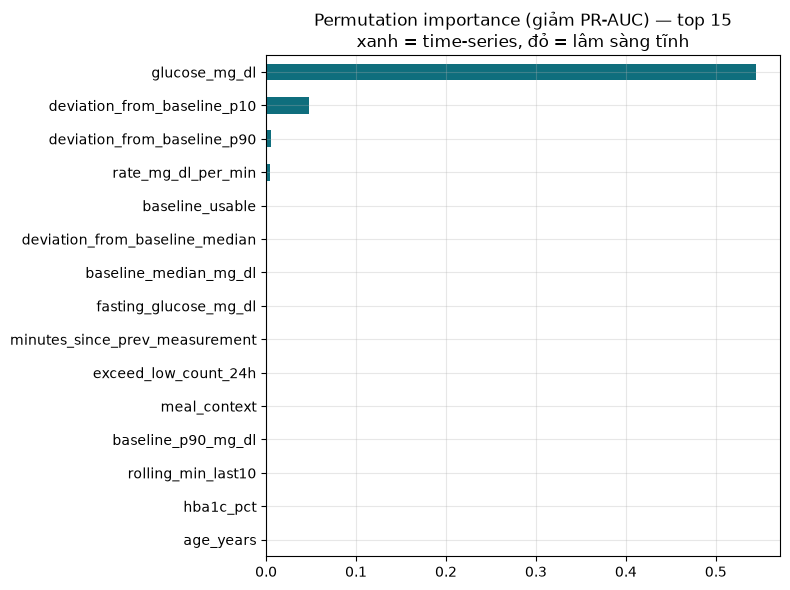

In [15]:
import joblib
from sklearn.inspection import permutation_importance

hgb_model = joblib.load(ARTIFACTS_DIR / "v1_hgb" / "model.joblib")
schema = json.loads((ARTIFACTS_DIR / "v1_hgb" / "feature_schema.json").read_text())
numeric, categorical = schema["numeric_features"], schema["categorical_features"]

BOOL_LIKE = [c for c in numeric if c.endswith("_is_missing") or c in (
    "baseline_usable", "caregiver_required_flag", "congestive_heart_failure_flag",
    "coronary_heart_disease_flag", "stroke_flag", "family_history_diabetes_flag",
)]
ft = feature_table.copy()
for c in BOOL_LIKE:
    ft[c] = ft[c].map({"True": 1, "False": 0, True: 1, False: 0}).astype(float)
for c in categorical:
    ft[c] = ft[c].astype("category")

eligible = ft[ft["eligible_for_binary_training"] == True].copy()
eligible["y_watch"] = eligible["y_watch"].astype(int)
val_sample = eligible[eligible["split"] == "validation"].sample(n=3000, random_state=1)

perm = permutation_importance(
    hgb_model, val_sample[numeric + categorical], val_sample["y_watch"].to_numpy(),
    scoring="average_precision", n_repeats=3, random_state=1, n_jobs=-1,
)
importance = pd.Series(perm.importances_mean, index=numeric + categorical).sort_values(ascending=False)

CLINICAL_FIELDS = {"hba1c_pct", "fasting_glucose_mg_dl", "ldl_mg_dl", "hdl_mg_dl",
                    "triglycerides_mg_dl", "sbp_mean", "dbp_mean",
                    "congestive_heart_failure_flag", "coronary_heart_disease_flag",
                    "stroke_flag", "family_history_diabetes_flag", "age_years", "bmi",
                    "sex", "caregiver_required_flag", "overall_data_quality_score",
                    "risk_group", "medication_hypoglycemia_risk"}
print("Tổng importance khối lâm sàng tĩnh:", importance[importance.index.isin(CLINICAL_FIELDS)].sum())
print("Tổng importance khối chuỗi thời gian:", importance[~importance.index.isin(CLINICAL_FIELDS)].sum())

fig, ax = plt.subplots(figsize=(8, 6))
top15 = importance.head(15).iloc[::-1]
colors = ["#b23b3b" if name in CLINICAL_FIELDS else "#0f6e7d" for name in top15.index]
top15.plot(kind="barh", ax=ax, color=colors)
ax.set_title("Permutation importance (giảm PR-AUC) — top 15\nxanh = time-series, đỏ = lâm sàng tĩnh")
plt.tight_layout()
plt.show()

### Bệnh nhân đo tự do, không theo lịch cố định — model phản ứng thế nào?

Tiếp nối mục 1.7: model có dùng `meal_context` và feature theo thời gian thực nên về thiết kế
KHÔNG giả định lịch đo cố định. Nhưng dữ liệu train gần như không có ca đo tự do thật (RANDOM
0,1%, thiếu meal_context 0 dòng — mục 1.7) — thử trực tiếp trên model đã train để xem nó phản
ứng ra sao với đúng ca đó.

In [16]:
sample_row = ft[(ft["split"] == "test") & (ft["eligible_for_binary_training"] == True)].iloc[0].copy()
X_original = pd.DataFrame([sample_row[numeric + categorical]])
for c in categorical:
    X_original[c] = X_original[c].astype(ft[c].dtype)

X_missing_context = X_original.copy()
new_categories = list(ft["meal_context"].cat.categories)
if "UNSPECIFIED" not in new_categories:
    new_categories = new_categories + ["UNSPECIFIED"]
X_missing_context["meal_context"] = pd.Categorical(["UNSPECIFIED"], categories=new_categories)

model_for_group = joblib.load(ARTIFACTS_DIR / "v1_hgb" / f"calibrated_{sample_row['risk_group']}.joblib")
try:
    p_original = model_for_group.predict_proba(X_original)[:, 1][0]
    p_missing = model_for_group.predict_proba(X_missing_context)[:, 1][0]
    print(f"meal_context thật ({sample_row['meal_context']}): P(WATCH) = {p_original:.4f}")
    print(f"meal_context rỗng -> UNSPECIFIED (0 ví dụ lúc train): P(WATCH) = {p_missing:.4f}")
    print(f"Chênh lệch: {abs(p_original - p_missing):.4f}")
    print("\n-> Model không crash trên category chưa từng thấy (HistGradientBoosting route nó vào\n"
          "   nhánh mặc định lúc split), nhưng KHÔNG có gì đảm bảo nhánh mặc định đó là quyết định\n"
          "   đúng — chỉ là không lỗi, không phải đã được kiểm chứng.")
except Exception as exc:
    print(f"Model từ chối/lỗi với category chưa từng thấy lúc train: {exc!r}")

meal_context thật (FASTING): P(WATCH) = 1.0000
meal_context rỗng -> UNSPECIFIED (0 ví dụ lúc train): P(WATCH) = 1.0000
Chênh lệch: 0.0000

-> Model không crash trên category chưa từng thấy (HistGradientBoosting route nó vào
   nhánh mặc định lúc split), nhưng KHÔNG có gì đảm bảo nhánh mặc định đó là quyết định
   đúng — chỉ là không lỗi, không phải đã được kiểm chứng.


**Kết luận:** model không crash, nhưng "không crash" khác với "đã kiểm chứng đúng". `meal_context`
đứng hạng 11/54 theo permutation importance nhưng giá trị gần như 0 (~7×10⁻⁷, cùng bậc với nhiễu) —
vì `deviation_from_baseline_p10/p90/median` đã ngầm mang thông tin bối cảnh bữa ăn (baseline được
tra theo đúng `meal_context`), nên bản thân cờ `meal_context` không cộng thêm nhiều tín hiệu mới.
Nói cách khác: model có "nhìn thấy" bối cảnh đo, chủ yếu qua baseline cá nhân theo từng bối cảnh,
không phải qua bản thân nhãn bối cảnh.

Rủi ro thật không phải model bỏ qua thời gian — mà là **hành vi ở vùng dữ liệu ngoài phân phối
train** (đo tự do, dồn dập, thiếu meal_context) chưa có gì để đối chiếu, vì synthetic 60 ngày mô
phỏng gần đúng lịch đo có cấu trúc của hệ thống nhắc lịch hiện tại (`notifications/defaults.py`,
6 lần/ngày theo bữa ăn), không mô phỏng hành vi tự do của bệnh nhân thật. Cần thêm vào Giai đoạn C:
tách kết quả shadow mode theo mức độ bất thường của thời điểm đo, không chỉ theo risk_group.

### Lớp 3 — dải cảnh báo sớm cá nhân

Invert model theo trục glucose cho hai bệnh nhân minh họa: một người baseline nằm
trong vùng an toàn, một người baseline đã cao hơn ngưỡng target_high=180 cố định.

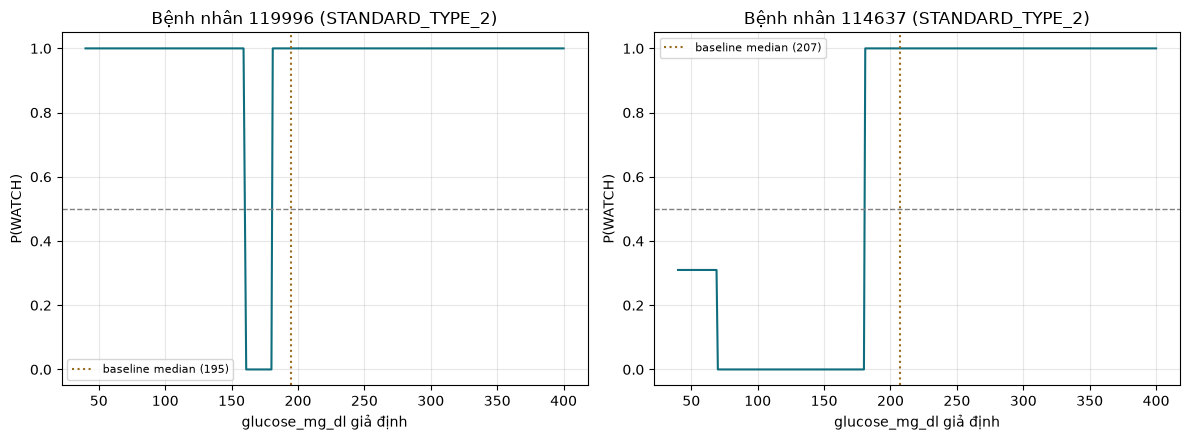

Bệnh nhân 119996 (baseline an toàn): {'anchor_glucose_mg_dl': 195.0, 'anchor_probability': 1.0, 'low_band_mg_dl': None, 'high_band_mg_dl': None, 'note': "P(WATCH) already >= threshold at the patient's own baseline — band not meaningful, abstain"}
Bệnh nhân 114637 (baseline đã cao): {'anchor_glucose_mg_dl': 207.0, 'anchor_probability': 1.0, 'low_band_mg_dl': None, 'high_band_mg_dl': None, 'note': "P(WATCH) already >= threshold at the patient's own baseline — band not meaningful, abstain"}


In [17]:
from personalized_band import build_candidate_frame, find_band, CATEGORICAL_COLUMNS

def show_patient_curve(patient_id, ax):
    row = ft[(ft["patient_id"] == patient_id) & (ft["split"] == "test")].sort_values("measured_at").iloc[-1]
    calibrator_path = ARTIFACTS_DIR / "v1_hgb" / f"calibrated_{row['risk_group']}.joblib"
    model = joblib.load(calibrator_path) if calibrator_path.exists() else hgb_model
    frame, candidates = build_candidate_frame(row, numeric, categorical)
    prob = model.predict_proba(frame[numeric + categorical])[:, 1]
    anchor = float(row["baseline_median_mg_dl"]) if pd.notna(row.get("baseline_median_mg_dl")) else float(row["glucose_mg_dl"])
    band = find_band(candidates, prob, anchor, 0.5)

    ax.plot(candidates, prob, color="#0f6e7d")
    ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
    ax.axvline(anchor, color="#9a6c1f", linestyle=":", label=f"baseline median ({anchor:.0f})")
    if band["low_band_mg_dl"]:
        ax.axvline(band["low_band_mg_dl"], color="#b23b3b", linewidth=1.5, label=f"low band ({band['low_band_mg_dl']:.0f})")
    if band["high_band_mg_dl"]:
        ax.axvline(band["high_band_mg_dl"], color="#b23b3b", linewidth=1.5, label=f"high band ({band['high_band_mg_dl']:.0f})")
    ax.set_title(f"Bệnh nhân {patient_id} ({row['risk_group']})")
    ax.set_xlabel("glucose_mg_dl giả định"); ax.set_ylabel("P(WATCH)")
    ax.legend(fontsize=8)
    return band

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
band_safe = show_patient_curve(119996, axes[0])
band_elevated = show_patient_curve(114637, axes[1])
plt.tight_layout()
plt.show()

print("Bệnh nhân 119996 (baseline an toàn):", band_safe)
print("Bệnh nhân 114637 (baseline đã cao):", band_elevated)

In [18]:
bands_sample = pd.read_csv(ML_DIR / "personalized_bands_sample.csv")
display(bands_sample)

,patient_id,risk_group,measured_at,actual_glucose_mg_dl,actual_status,anchor_glucose_mg_dl,anchor_probability,low_band_mg_dl,high_band_mg_dl,note
0,114637,STANDARD_TYPE_2,2026-02-10 14:40:00,247.0,WATCH,207.0,1.0,NaN,NaN,P(WATCH) already >= threshold at the patient's...
1,115850,STANDARD_TYPE_2,2026-02-19 14:38:00,245.0,WATCH,245.0,1.0,NaN,NaN,P(WATCH) already >= threshold at the patient's...
2,109843,STANDARD_TYPE_2,2026-02-20 20:30:00,184.0,WATCH,188.0,1.0,NaN,NaN,P(WATCH) already >= threshold at the patient's...
3,115985,OLDER_OR_HIGH_RISK,2026-02-28 06:44:00,244.0,WATCH,246.0,1.0,NaN,NaN,P(WATCH) already >= threshold at the patient's...
4,118815,STANDARD_TYPE_2,2026-02-28 13:53:00,226.0,WATCH,231.0,1.0,NaN,NaN,P(WATCH) already >= threshold at the patient's...
5,113026,STANDARD_TYPE_2,2026-02-28 14:06:00,235.0,WATCH,235.0,1.0,NaN,NaN,P(WATCH) already >= threshold at the patient's...
6,124697,OLDER_OR_HIGH_RISK,2026-02-28 17:44:00,246.0,WATCH,235.0,1.0,NaN,NaN,P(WATCH) already >= threshold at the patient's...
7,119400,STANDARD_TYPE_2,2026-02-28 20:10:00,247.0,WATCH,226.0,1.0,NaN,NaN,P(WATCH) already >= threshold at the patient's...
8,110849,OLDER_OR_HIGH_RISK,2026-03-01 06:53:00,225.0,WATCH,239.0,1.0,NaN,NaN,P(WATCH) already >= threshold at the patient's...
9,115647,OLDER_OR_HIGH_RISK,2026-03-01 07:10:00,185.0,WATCH,201.0,1.0,NaN,NaN,P(WATCH) already >= threshold at the patient's...


## Phần 4 — Giai đoạn C: an toàn & shadow mode

`data/ml/personalized_watch/serving.py` là hàm suy luận an toàn duy nhất mọi nơi phải đi qua —
kiểm DANGER trước, ML chỉ được gọi khi không phải DANGER. Chạy lại test + shadow mode ở đây.

In [19]:
result = subprocess.run(
    [sys.executable, "-m", "pytest", str(ML_DIR / "test_danger_precedence.py"), "-v"],
    capture_output=True, text=True, cwd=REPO_ROOT,
)
print(result.stdout[-2500:])

============================= test session starts ==============================
platform darwin -- Python 3.11.9, pytest-9.1.1, pluggy-1.6.0 -- /Users/phamminh/Desktop/phamminh/AIThucChien/P-158/.venv/bin/python
cachedir: .pytest_cache
rootdir: /Users/phamminh/Desktop/phamminh/AIThucChien/P-158
plugins: langsmith-0.11.0, asyncio-1.4.0, anyio-4.14.2
asyncio: mode=Mode.STRICT, debug=False, asyncio_default_fixture_loop_scope=None, asyncio_default_test_loop_scope=function
collecting ... collected 8 items

data/ml/personalized_watch/test_danger_precedence.py::test_danger_gate_never_calls_ml[53.9-54-250-DANGER] PASSED [ 12%]
data/ml/personalized_watch/test_danger_precedence.py::test_danger_gate_never_calls_ml[0.0-54-250-DANGER] PASSED [ 25%]
data/ml/personalized_watch/test_danger_precedence.py::test_danger_gate_never_calls_ml[250.1-54-250-DANGER] PASSED [ 37%]
data/ml/personalized_watch/test_danger_precedence.py::test_danger_gate_never_calls_ml[600.0-54-250-DANGER] PASSED [ 50%]
data/ml/per

In [20]:
cmd = [sys.executable, str(FINAL_DIR / "run_shadow_mode.py")]
result = subprocess.run(cmd, capture_output=True, text=True, cwd=REPO_ROOT)
print(result.stdout)
if result.returncode != 0:
    print(result.stderr)

Overall agreement (rule vs ML, safety-gated): 0.9996826171875

By timing bucket (all splits):
  no_prior_measurement     n=    73  agreement=1.0000
  normal_30min_3h          n= 28033  agreement=0.9996
  sparse_gt_3h             n= 51503  agreement=0.9997
  very_tight_lt_30min      n=  2311  agreement=1.0000

By timing bucket (test split / patient-holdout only):
  no_prior_measurement     n=    15  agreement=1.0000
  normal_30min_3h          n=  5856  agreement=0.9986
  sparse_gt_3h             n= 10540  agreement=0.9992
  very_tight_lt_30min      n=   497  agreement=1.0000

By meal_context group:
  irregular    n=   918  agreement=1.0000
  structured   n= 81002  agreement=0.9997

wrote data/ml/personalized_watch/shadow_mode_report.json



### Đo tự do có được xử lý an toàn không?

Trực tiếp trả lời câu hỏi review ở mục 1.7/3: tách agreement rule-vs-ML theo mức bất thường
của thời điểm đo.

In [21]:
shadow_report = json.loads((ML_DIR / "shadow_mode_report.json").read_text())

timing_df = pd.DataFrame(shadow_report["by_timing_bucket"]).T[["n", "agreement_rate"]]
context_df = pd.DataFrame(shadow_report["by_meal_context_group"]).T[["n", "agreement_rate"]]
print("Theo mức bất thường của khoảng cách đo:")
display(timing_df)
print("\nTheo bối cảnh bữa ăn (structured vs RANDOM/EVENT_RECOVERY):")
display(context_df)

Theo mức bất thường của khoảng cách đo:


,n,agreement_rate
no_prior_measurement,73,1.0
normal_30min_3h,28033,0.999608
sparse_gt_3h,51503,0.999709
very_tight_lt_30min,2311,1.0



Theo bối cảnh bữa ăn (structured vs RANDOM/EVENT_RECOVERY):


,n,agreement_rate
irregular,918,1.0
structured,81002,0.999679


Agreement vẫn cao (≥99,96%) kể cả ở nhóm đo dồn dập (<30 phút) và bối cảnh bất thường — nhưng đây
là các ca **đã tồn tại** trong dữ liệu synthetic dù hiếm, không chứng minh được gì cho ca hoàn toàn
chưa từng xuất hiện (meal_context rỗng hoàn toàn, 0 ví dụ — mục 1.7). Kết luận: an toàn cho các ca
lệch nhịp còn có bối cảnh, chưa kiểm chứng được cho ca thiếu bối cảnh hoàn toàn.

**Bước còn lại của Giai đoạn C (bước 11) cần người thật:** bác sĩ xem các ca ML/rule lệch nhau
nhiều nhất trước khi bàn production gate — không tự động hoá được trong notebook này.

## Tóm tắt & các điểm còn cần quyết định

- **Giai đoạn A-B đã chạy xong và khớp với chẩn đoán ban đầu** — nhãn, tỉ lệ WATCH/NORMAL/DANGER,
  tương quan HbA1c/danger_rate đều khớp số đã thấy khi phân tích thủ công.
- **PR-AUC ~0,9999 không phải bằng chứng hiệu quả lâm sàng** — permutation importance xác nhận
  `glucose_mg_dl` một mình gánh phần lớn, khối lâm sàng tĩnh đóng góp ≈ 0, vì rule hiện tại chưa
  hề dùng khối đó. Giá trị thật của khối lâm sàng chỉ đo được sau khi có nhãn bác sĩ thật.
- **Lớp 3 (dải cảnh báo sớm) chỉ định nghĩa được khi baseline bệnh nhân nằm trong vùng an toàn.**
  Với nhóm baseline đã vượt target_high=180 cố định, không có "dải an toàn" nào để suy ra — bằng
  chứng cụ thể cho câu hỏi mở về nhóm DANGER-nặng ở `docs/ML_PERSONALIZED_WATCH_SYSTEM_PLAN.md` mục 4.
- **Bệnh nhân đo tự do (giờ bất kỳ, dồn dập, thiếu meal_context) là vùng ngoài phân phối train** —
  đã kiểm `codebase/backend/health/schemas.py`: không có gì chặn việc này ngoài đời, nhưng dữ liệu
  synthetic mô phỏng gần đúng lịch đo có cấu trúc (RANDOM chỉ 0,1%, 0 dòng thiếu meal_context). Model
  không crash ở vùng này nhưng chưa được kiểm chứng — cần thêm vào Giai đoạn C.

- **Giai đoạn C xong (bước 9-10):** safety gate đúng 100% trên toàn bộ DANGER thật, agreement
  rule-vs-ML 99,97% tổng thể — kể cả ở các ca đo lệch nhịp đã tồn tại trong dữ liệu, nhưng chưa
  kiểm chứng được ca thiếu bối cảnh hoàn toàn (0 ví dụ để test).

Các điểm còn cần bàn (không tự chốt trong notebook này): xem mục 4 của plan doc. Bước 11 (review
bác sĩ) và Giai đoạn D-E (đưa vào backend sống + Zalo) cần người quyết, chưa làm.